# Exercises XP: Student Notebook

For each exercise, the **Instructions** from the plateform are guided, and the **Guidance** explains exactly what you must do to complete the task.

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. Run the cells from top to bottom (Shift+Enter runs one cell).
3. Exercise 2 downloads the Loan Predication dataset from GitHub, so I do not need to upload the file myself.


## What you will learn
- How to clearly define and articulate a machine learning problem statement.

- The process of data collection, including identifying relevant data types and potential data sources.
Skills in feature selection and justification for machine learning models, particularly in the context of loan default prediction.

- Understanding of different types of machine learning models and their suitability for various real-world scenarios.

- Techniques and strategies for evaluating the performance of different machine learning models, including choosing appropriate metrics and understanding their implications.

## What you will create
- A detailed problem statement and data collection plan for a loan default prediction project, including identification of key data types and sources.
- A comprehensive feature selection analysis for a hypothetical loan default prediction dataset.
- A theoretical evaluation strategy for three different types of machine learning models, addressing the unique challenges and metrics relevant to each model type.
- Thoughtful analyses and justifications for choosing specific machine learning approaches for varied scenarios such as stock price prediction, library organization, and robot navigation.
- A document or presentation that showcases your understanding and approach to evaluating and optimizing machine learning models in diverse contexts.

## 🌟 Exercise 1 : Defining the Problem and Data Collection for Loan Default Prediction

### Instructions
- Write a clear problem statement for predicting loan defaults.
- Identify and list the types of data you would need for this project (e.g., personal details of applicants, credit scores, loan amounts, repayment history).
- Discuss the sources where you can collect this data (e.g., financial institution’s internal records, credit bureaus).

**Expected Output:** A document detailing the problem statement and a comprehensive plan for data collection, including data types and sources.

### Guidance
- Please write your answer as a short document. Begin by stating the prediction objective in a complete sentence that names the target variable and the decision it will support. Then, describe the data types you would collect in complete sentences. For each data type, explain in one sentence why it could help predict loan defaults. 

- After that, name realistic data sources in complete sentences, and briefly describe how you would obtain or integrate each source. 

- Finally, include one paragraph that explains risks and constraints such as privacy, regulation, data quality, sampling bias, and governance.

### Your answer

#### Problem statement
I want to build a machine learning model that predicts whether a loan applicant is likely to default on the loan. The target variable is binary: **default = 1** (the applicant is likely to default) or **default = 0** (the applicant is likely to repay). The bank can use this prediction to decide whether to approve the application, how much money to lend, and what interest rate or extra checks to apply.

#### Data I would collect
I would collect several types of information, because each type explains a different part of the risk:

- **Personal details of the applicant** (age, job type, years employed, education, marital status). These features describe how stable the person’s work and household situation are, which can affect their ability to keep paying.
- **Income and current debts** (monthly or yearly income, other loans, credit-card balances). These features show whether the person can realistically afford the new monthly payment.
- **Credit scores and credit history** (credit score, number of late payments, previous defaults, how much of the available credit is already used). These features summarise how reliably the person repaid money in the past, which is often a strong signal of future default.
- **Loan details** (requested amount, term in months, interest rate, purpose of the loan, and whether there is collateral such as a property). A larger loan or a longer term can change the chance that repayment becomes difficult later.
- **Repayment history with this institution**, if the person already has an account there. Someone who already missed payments with the same bank is more likely to have problems again.

#### Where I can collect this data
I can collect most of this data from the **financial institution’s own internal records**: application forms, approved loans, and whether those loans were repaid on time. The bank would extract an anonymised table from its database.

I would also use **credit bureaus** (for example a national credit register) to obtain the credit score and the public credit history. The bank can request this only with the applicant’s consent, usually at the moment the person applies.

The **application form** itself is another source: the applicant reports income, employment, the loan purpose and the amount they want. If the loan is secured, **property or collateral records** can add the value and the location of the asset (this is similar to the Property_Area column in the exercise dataset).

#### Risks and constraints
I must protect the applicants’ privacy and follow data-protection rules such as GDPR, so I should not keep extra personal identifiers that the model does not need. Historical data can also be biased: the bank already rejected some people in the past, so the training sample is not a random group of every possible applicant. Sensitive attributes such as gender should be handled carefully so the model does not discriminate. Missing values, typing mistakes and outdated records can reduce data quality. Finally, the bank needs clear governance: who is allowed to see the data, how long it is stored, and how a rejection can be explained to an applicant.


## 🌟 Exercise 2 : Feature Selection and Model Choice for Loan Default Prediction

### Instructions
From this dataset, identify which features might be most relevant for predicting loan defaults.
Justify your choice of features.

### Guidance
- First, identify the features that you believe are most relevant, and write their names in a sentence. 
Then, provide a justification in complete sentences that explains how each selected feature relates to the likelihood of default. 

- If you decide to exclude common features, write one sentence for each excluded feature to explain why it is not appropriate in this context. 

- Conclude with two complete sentences that explain how you would encode categorical features and how you would impute missing values.

In [1]:

# I download the official "Loan Predication" zip from the course GitHub.
# The same file also lives in my computer's Datasets folder, but this URL
# lets the notebook run in Colab without any extra upload.
import io
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import seaborn as sns

DATA_URL = (
    "https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/"
    "Week%204/Day%201/Loan%20Predication.zip"
)

with urllib.request.urlopen(DATA_URL) as response:
    raw = response.read()

with zipfile.ZipFile(io.BytesIO(raw)) as zf:
    csv_name = zf.namelist()[0]
    print("File inside the zip:", csv_name)
    df = pd.read_csv(zf.open(csv_name))

print("Shape (rows, columns):", df.shape)
print("\nColumns:")
print(list(df.columns))
print("\nFirst 5 rows:")
display(df.head())
print("\nMissing values in each column:")
print(df.isna().sum())
print("\nTarget (Loan_Status) counts:")
print(df["Loan_Status"].value_counts(dropna=False))
print("\nNote: Y means the loan was approved and N means it was not approved.")
print("This table has no column that says 'this person defaulted'.")
print("I will use Loan_Status = N as the riskier / not-approved outcome.")


File inside the zip: train_u6lujuX_CVtuZ9i (1).csv
Shape (rows, columns): (614, 13)

Columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

First 5 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Missing values in each column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Target (Loan_Status) counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Note: Y means the loan was approved and N means it was not approved.
This table has no column that says 'this person defaulted'.
I will use Loan_Status = N as the riskier / not-approved outcome.


In [2]:

# I create a 0/1 column so I can compute a "not-approved rate"
# (the closest thing this table has to a default rate).
df["not_approved"] = (df["Loan_Status"] == "N").astype(int)

print("Overall not-approved rate: "
      f"{df['not_approved'].mean():.1%} "
      f"({df['not_approved'].sum()} out of {len(df)})")

# Categorical features: how often was the loan not approved in each group?
cat_cols = [
    "Gender", "Married", "Dependents", "Education",
    "Self_Employed", "Credit_History", "Property_Area",
]
for col in cat_cols:
    rates = (
        df.groupby(col, dropna=False)["not_approved"]
        .agg(not_approved_rate="mean", n="size")
        .sort_values("not_approved_rate", ascending=False)
    )
    rates["not_approved_rate"] = (rates["not_approved_rate"] * 100).round(1)
    print(f"\nNot-approved rate by {col} (percent):")
    print(rates)

# Numeric features: typical values for approved vs not-approved loans
num_cols = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"
]
print("\nNumeric features by Loan_Status:")
display(df.groupby("Loan_Status")[num_cols].agg(["mean", "median"]).round(1))


Overall not-approved rate: 31.3% (192 out of 614)

Not-approved rate by Gender (percent):
        not_approved_rate    n
Gender                        
NaN                  38.5   13
Female               33.0  112
Male                 30.7  489

Not-approved rate by Married (percent):
         not_approved_rate    n
Married                        
No                    37.1  213
Yes                   28.4  398
NaN                    0.0    3

Not-approved rate by Dependents (percent):
            not_approved_rate    n
Dependents                        
NaN                      40.0   15
3+                       35.3   51
1                        35.3  102
0                        31.0  345
2                        24.8  101

Not-approved rate by Education (percent):
              not_approved_rate    n
Education                           
Not Graduate               38.8  134
Graduate                   29.2  480

Not-approved rate by Self_Employed (percent):
               not_approved

ApplicantIncome         CoapplicantIncome         LoanAmount  \
                       mean  median              mean  median       mean   
Loan_Status                                                                
N                    5446.1  3833.5            1877.8   268.0      151.2   
Y                    5384.1  3812.5            1504.5  1239.5      144.3   

                   Loan_Amount_Term         
            median             mean median  
Loan_Status                                 
N            129.0            344.1  360.0  
Y            126.0            341.1  360.0

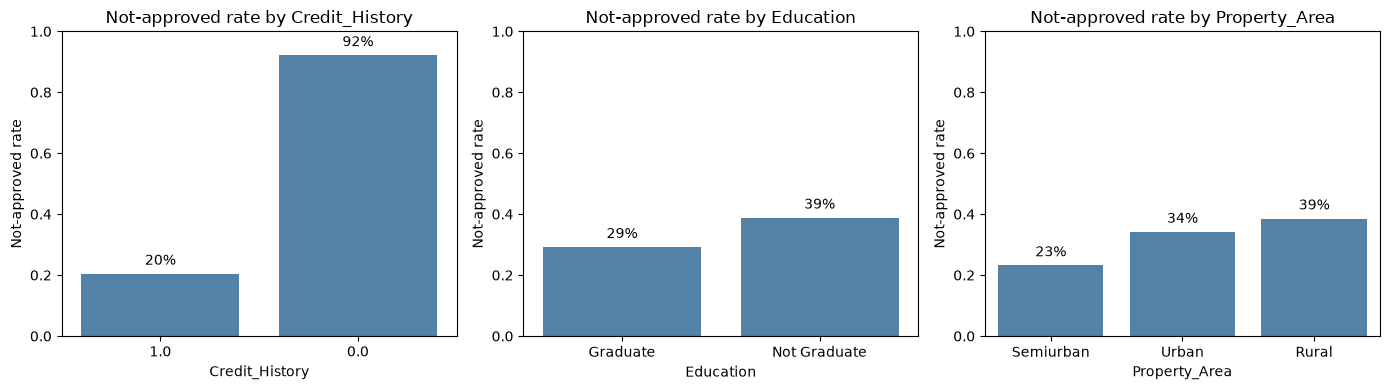

Selected features:
- Credit_History
- Education
- Married
- Property_Area
- ApplicantIncome
- CoapplicantIncome
- LoanAmount
- Loan_Amount_Term
- Dependents

I would also build two extra features from the columns I already have:
- TotalIncome = ApplicantIncome + CoapplicantIncome
- Loan_to_Income = LoanAmount / TotalIncome


In [3]:

# Bar charts help me see which features are actually related to the outcome.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_cols = ["Credit_History", "Education", "Property_Area"]

for ax, col in zip(axes, plot_cols):
    rates = df.groupby(col)["not_approved"].mean().sort_values()
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color="steelblue")
    ax.set_title(f"Not-approved rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Not-approved rate")
    ax.set_ylim(0, 1)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.03, f"{v:.0%}", ha="center")

plt.tight_layout()
plt.show()

# These are the columns I keep as features, based on the tables and charts above.
selected_features = [
    "Credit_History",
    "Education",
    "Married",
    "Property_Area",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Dependents",
]
print("Selected features:")
for name in selected_features:
    print("-", name)

print("\nI would also build two extra features from the columns I already have:")
print("- TotalIncome = ApplicantIncome + CoapplicantIncome")
print("- Loan_to_Income = LoanAmount / TotalIncome")


### Your justification

I loaded the course **Loan Predication** dataset (614 rows and 13 columns). The columns are `Loan_ID`, `Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`, `ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Loan_Amount_Term`, `Credit_History`, `Property_Area` and the target `Loan_Status`. The target is Y (approved) or N (not approved). The table does not contain a real “defaulted” column, so I studied the **not-approved rate** (the share of N) as the closest measure of loan risk in this file.

The features I find most relevant are **Credit_History, Education, Married, Property_Area, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term and Dependents**.

**Credit_History** is by far the strongest feature. When credit history is 0, about **92%** of the applications are not approved. When credit history is 1, only about **20%** are not approved. That is a very large difference, so past credit behaviour is clearly linked to the outcome.

**Education** also helps: about **39%** of applicants who are not graduates are not approved, compared with about **29%** of graduates. A graduate may have a more stable income path, which can lower risk.

**Married** applicants are not approved about **28%** of the time, while unmarried applicants are not approved about **37%** of the time. A second adult in the household (and often a coapplicant income) can make repayment more realistic.

**Property_Area** matters as well. Rural applications are not approved most often (about **39%**), then Urban (about **34%**), then Semiurban (about **23%**). Location can be related to income level, property value or the bank’s own policy.

**ApplicantIncome**, **CoapplicantIncome** and **LoanAmount** describe whether the requested loan is affordable. The raw averages are not as dramatic as Credit_History (approved and not-approved incomes look fairly similar), but together they let me build more useful ratios, such as total household income and loan amount compared with income. A person who asks for a large loan relative to income is under more pressure each month.

**Loan_Amount_Term** is the number of months the person has to repay. A very short or very long term can change the monthly burden, so I keep it.

**Dependents** has a smaller effect (the not-approved rate is a bit lower when there are 2 dependents), but the number of dependents still affects household expenses, so I keep it.

I would exclude **Loan_ID** because it is only an identifier. It names the row and cannot explain why someone is risky.

I would exclude **Gender** for two reasons. First, the not-approved rates are almost the same (about 31% for men and 33% for women), so it is a weak predictor. Second, gender is a sensitive attribute, and a bank should not use it to approve or reject loans.

I would exclude **Self_Employed** because the not-approved rates are almost identical (about 31.4% if not self-employed and 31.7% if self-employed). It does not add useful information in this table.

To prepare the data, I would encode the categorical features (`Married`, `Education`, `Property_Area`, `Dependents`) with one-hot encoding, and I would leave `Credit_History` as 0 or 1 because it is already numeric. I would impute missing numeric values such as `LoanAmount` and `Loan_Amount_Term` with the median, and I would impute missing categorical values with the most frequent category (the mode). For `Credit_History`, which has 50 missing values and is very important, I would also add a missing-value indicator so the model can learn that “history unknown” is different from 0 or 1.


## 🌟 Exercise 3 : Training, Evaluating, and Optimizing the Model

### Instructions
Which model(s) would you pick for a Loan Prediction ?
Outline the steps to evaluate the model’s performance, mentioning specific metrics that would be relevant to evaluate the model.

### Guidance
- Begin by naming one or two candidate models in a complete sentence and explain why each model is suitable for this problem. 

- Next, describe an evaluation plan in complete sentences that covers the data split, the cross-validation strategy, the metrics you will report, and how you will choose a decision threshold. 

- Then, explain in complete sentences how you will address class imbalance using stratification, class weights, or resampling. 

- Finally, state in one or two complete sentences how you would iterate on hyperparameters to improve performance while avoiding data leakage.

In [4]:

# This piece of code is already prefilled, run it to execute it and see the results.
# It demonstrates standard classification metrics for binary loan default prediction.

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report

# Please replace these placeholders with your true labels and predicted probabilities.
y_true = [0,1,0,1,0,0,1,0,1,0]            # placeholder labels
y_pred_proba = [0.05,0.80,0.10,0.65,0.20,0.15,0.70,0.30,0.85,0.25]  # placeholder probabilities

# You should set a decision threshold that reflects the precision–recall trade-off for your business case.
threshold = 0.5
y_pred = [1 if p >= threshold else 0 for p in y_pred_proba]

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_pred_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_true, y_pred_proba), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification report:\n", classification_report(y_true, y_pred, zero_division=0))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0
PR-AUC (Average Precision): 1.0

Confusion matrix:
 [[6 0]
 [0 4]]

Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         4

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



### Your answer

I would start with **logistic regression** as my first model. This is a yes-or-no problem (approved vs not approved, or default vs no default), and logistic regression is built for binary classification. The coefficients are also easier to explain to a bank: I can say which features increase or decrease the estimated risk.

I would then try a **random forest** as a second model. A random forest can capture non-linear patterns and interactions (for example credit history together with income) without me creating every combination by hand. If both models give a similar story, I trust the result more.

My evaluation plan starts with a **stratified train/test split**, about 80% for training and 20% for testing. Stratified means both parts keep the same share of Y and N, which matters because this dataset is a bit imbalanced (about 69% approved and 31% not approved). On the training set I would use **stratified k-fold cross-validation** (for example 5 folds) so every score is an average over several splits, not one lucky split.

I would report **accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC (average precision) and the confusion matrix**. Accuracy alone is not enough: a model that always predicts “approved” would already be right about 69% of the time. For loan risk I would pay special attention to **recall of the risky class**, because missing a likely default (a false negative) usually costs the bank more than turning down a good customer (a false positive). I would still look at precision, so I do not reject too many good applicants. I would choose the **decision threshold** by looking at this trade-off, not by automatically using 0.5.

To handle class imbalance I would **stratify** every split and I would try **class weights** (for example `class_weight="balanced"` in scikit-learn) so the model pays more attention to the smaller risky class. If needed I could also resample the training data, but I would never resample the test set.

To improve the model I would tune hyperparameters with a grid search or a random search **inside cross-validation on the training data only**. I would not touch the test set until the very end. That way information from the test set cannot leak into the training process, and the final test score stays honest.


## 🌟 Exercise 4 : Designing Machine Learning Solutions for Specific Problems

### Instructions
For each of these scenario, decide which type of machine learning would be most suitable. Explain.

Predicting Stock Prices : predict future prices
Organizing a Library of Books : group books into genres or categories based on similarities.
Program a robot to navigate and find the shortest path in a maze.

### Guidance
Please identify the appropriate machine learning paradigm for each scenario in complete sentences and justify your choice. 

For each scenario, write one complete sentence that describes the input data, one complete sentence that describes the output, and one complete sentence that describes the learning signal or objective.

### Your answer

**Predicting stock prices.** I would use **supervised learning**, specifically **regression**. The goal is to predict a future number (the price), and history already gives me the true prices that I can use as labels. The input data would be past prices, trading volume and other market features. The output would be a predicted future price, which is a continuous number. The learning signal is the real historical price, so the model can measure how far its prediction was from the true value and then adjust.

**Organizing a library of books.** I would use **unsupervised learning**, specifically **clustering**. The task is to group books by similarity into genres or categories, and I may not have a ready-made correct genre label for every book. The input data would be information about each book, such as the title, description or keywords. The output would be a group or cluster that represents a genre-like category. The learning signal is similarity between books, not a pre-written right answer for each book.

**Programming a robot to navigate a maze.** I would use **reinforcement learning**. The robot should learn by trying actions and receiving a reward or a penalty, rather than by being shown the correct move for every position in advance. The input data would be the current state, for example the robot’s position and the walls it can see. The output would be the next action, such as move left, right, forward or back. The learning signal is a reward for reaching the exit and a small penalty for each extra step, so the robot is encouraged to find a shorter path.


## 🌟 Exercise 5 : Designing an Evaluation Strategy for Different ML Models

### Instructions
- Select three types of machine learning models: one from supervised learning (e.g., a classification model), one from unsupervised learning (e.g., a clustering model), and one from reinforcement learning. - For the supervised model, outline a strategy to evaluate its performance, including the choice of metrics (like accuracy, precision, recall, F1-score) and methods (like cross-validation, ROC curves).
- For the unsupervised model, describe how you would assess the effectiveness of the model, considering techniques like silhouette score, elbow method, or cluster validation metrics.
- For the reinforcement learning model, discuss how you would measure its success, considering aspects like cumulative reward, convergence, and exploration vs. exploitation balance.
- Address the challenges and limitations of evaluating models in each category.

### Guidance
- Please write a separate paragraph for each of the three model categories. 
- In the supervised paragraph, describe your validation plan and list the metrics you will report in complete sentences. 
- In the unsupervised paragraph, explain how you would measure cluster quality or structure in complete sentences and mention any diagnostic plots. 
- In the reinforcement learning paragraph, describe how you would track cumulative reward, assess convergence, and balance exploration and exploitation using complete sentences. 
Conclude with one complete sentence per category that states a key evaluation challenge.

In [5]:

# This piece of code is already prefilled, run it to execute it and see the results.
# Supervised classification metrics template with placeholders.

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# Replace these placeholders with your real outputs.
y_true = [0,1,1,0,1,0,0,1,0,1]
y_pred_proba = [0.1,0.7,0.8,0.2,0.6,0.3,0.4,0.9,0.2,0.85]
threshold = 0.5
y_pred = [1 if p >= threshold else 0 for p in y_pred_proba]

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_pred_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_true, y_pred_proba), 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0
PR-AUC (Average Precision): 1.0


In [6]:

# This piece of code is already prefilled, run it to execute it and see the results.
# Unsupervised clustering metrics template with synthetic data.

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=300, centers=3, random_state=42)
kmeans = KMeans(n_clusters=3, n_init="auto", random_state=42)
labels = kmeans.fit_predict(X)
sil = silhouette_score(X, labels)
print("Silhouette score (higher is better):", round(sil, 4))

print("Please explain in complete sentences when you would use the elbow method and how you would interpret it.")

Silhouette score (higher is better): 0.848
Please explain in complete sentences when you would use the elbow method and how you would interpret it.


### Your answer

**Supervised learning.** I would evaluate a **classification model**, for example logistic regression that predicts loan default or loan approval. I would split the data with a stratified train/test split and then use stratified k-fold cross-validation on the training set. I would report accuracy, but I would not stop there: I would also report precision, recall, F1-score, ROC-AUC and the confusion matrix, and I would draw an ROC curve to see the trade-off between true positives and false positives at many thresholds. A key evaluation challenge is class imbalance and threshold choice: accuracy can look good even if the model misses most of the risky cases.

**Unsupervised learning.** I would evaluate a **clustering model**, for example K-Means that groups customers into segments. Because there are no true labels, I cannot use accuracy. I would try several values of K and use the **elbow method** (I plot how the within-cluster error decreases as K grows, and I look for a bend) together with the **silhouette score** (higher usually means clearer, better-separated clusters). I would also look at the clusters with charts or summary tables to check whether they make business sense. A key evaluation challenge is that there is no single correct number of clusters, so a good silhouette score does not automatically mean the groups are useful.

**Reinforcement learning.** I would evaluate an agent that learns a task such as finding the exit of a maze. I would track the **cumulative reward** of each episode and plot it over time to see whether performance improves and then **converges** (the curve flattens instead of jumping around). I would also watch the balance between **exploration** (trying new actions, for example with a higher epsilon in epsilon-greedy) and **exploitation** (using the best action the agent knows so far). Early on I want more exploration; later I want more exploitation. A key evaluation challenge is that rewards can be delayed and noisy, so it is hard to know whether the agent found a truly good strategy or only memorised one particular maze.
